# Exploración Aire Valle de Aburrá: ¿se puede pronosticar el PM2.5 del día siguiente?

Spike de factibilidad de datos (no es el proyecto final). Predicción del **promedio diario de PM2.5** del valle con datos horarios de SIATA, meteorología de Open-Meteo y calendario.

Cada afirmación se marca como **[VERIFICADO]** (lo vimos en los datos) o **[SUPUESTO]**.

## Acceso a los datos

| Fuente | Resultado |
|---|---|
| datos.gov.co (catálogo) | Ningún dataset de AMVA ni de SIATA. Existe SISAIRE del IDEAM (`g4t8-zkc3`): horario, incluye estaciones del AMVA, pero solo llega hasta 2024-12-31. |
| siata.gov.co | La sección "Descargar información" está deshabilitada y el único enlace de descarga es de un portal con login. Solo hay informes diarios en PDF. No se encontró API ni CSV. |
| **datos.siata.gov.co** (Dataverse) | Dataset "Material Particulado - PM2.5": 162 archivos mensuales, 2013-01 a 2026-06, públicos (0 restringidos). **Se descargó a mano** desde el navegador porque su `robots.txt` prohíbe el acceso automatizado (`Disallow: /`). Es la fuente que se usa aquí. |
| OpenAQ v3 | Respondió 401: exige API key. No se solicitó. |
| Open-Meteo (archive) | Sin key. Se usa para la meteorología. |

## Términos y condiciones del repositorio SIATA (resumen de la versión leída)

El PDF se titula **"V1 - BORRADOR"** (abril 2026). La sección de licencia dice textualmente "licencia **XXXX**": la licencia concreta no está definida. Las condiciones relevantes:

- **Uso académico: permitido.** La información pública es de acceso libre y gratuito, sin registro, "incluyendo investigación científica, trabajo académico, desarrollo de proyectos" (6.1).
- **Atribución: obligatoria**, con identificación del conjunto de datos, SIATA como fuente y la dirección del repositorio (6.3 y 8). Cita sugerida: *Sistema de Alerta Temprana de Medellín y el Valle de Aburrá (SIATA), AMVA. "Material Particulado - PM2.5" (v4.0) [conjunto de datos]. Repositorio de Datos SIATA. https://doi.org/10.83041/AUWZWT, https://datos.siata.gov.co/*
- **Prohibido sin autorización escrita del AMVA**: (i) uso comercial directo; (ii) alterar o falsificar los datos descargados (los productos derivados deben distinguirse de los datos originales); (iii) usar los datos, públicos o no, para **entrenar modelos de IA/ML "con fines comerciales"** (sección 6.3). Un proyecto académico sin fines comerciales no cae en (iii), pero cualquier despliegue comercial sí.
- **Descargas automatizadas**: los usuarios deben abstenerse de "solicitudes automatizadas masivas sin autorización previa" y el uso de "robots, scripts o cualquier otro mecanismo de descarga automatizada **debe ser coordinado previamente con el equipo técnico del SIATA**" (11.2). Esto afecta directamente la estrategia de reajuste automático.
- **Redistribución / publicar los datos en un repositorio**: los términos solo prohíben expresamente redistribuir la información de **acceso controlado**. Para la pública remiten a la licencia, que está sin definir ("XXXX"). Por prudencia los datos no se suben al repositorio (`data/raw/` va en el `.gitignore`) y se referencia el DOI.
- Datos "tal cual" (*as is*), sin garantía de idoneidad; el usuario debe verificar que son apropiados para su uso (11.2 y 11.3).
- Contacto: `contacto@siata.gov.co` (consultas) y `solicitud.datos@siata.gov.co` (solicitudes formales).

In [1]:
import time, json, math
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import requests
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 80)

RAIZ = Path("data/raw")
SIATA = RAIZ / "siata_pm25" / "extraido" / "PM2.5"
METEO = RAIZ / "openmeteo"
METEO.mkdir(exist_ok=True)
SEED = 42
proc = psutil.Process()


def ram(etiqueta):
    mi = proc.memory_info()
    print(f"[RAM] {etiqueta}: actual {mi.rss / 1e6:.0f} MB | pico {getattr(mi, 'peak_wset', mi.rss) / 1e6:.0f} MB")


ram("inicio")

[RAM] inicio: actual 141 MB | pico 141 MB


## 1. Carga de SIATA (PM2.5 horario)

162 CSV mensuales en formato ancho: `fecha_hora` y una columna por estación (código `MUN-SITIO`). Se unen en una sola tabla horaria.
**Unidades**: se toman como µg/m³ **[VERIFICADO indirectamente]**: los niveles (mediana ~17) coinciden con los de los informes diarios de SIATA; el dataset no las declara en los archivos.

In [2]:
archivos = sorted(SIATA.rglob("Estaciones_PM2.5_*.csv"))
print("archivos:", len(archivos))
partes = [pd.read_csv(f, parse_dates=["fecha_hora"], index_col="fecha_hora") for f in archivos]
horario = pd.concat(partes).sort_index()
assert horario.index.is_unique
idx = pd.date_range(horario.index.min(), horario.index.max(), freq="h")
print("horas en el rango:", len(idx), "| filas:", len(horario), "| horas sin fila:", len(idx.difference(horario.index)))
horario = horario.reindex(idx)
horario.index.name = "fecha_hora"
print("estaciones (columnas):", horario.shape[1], "| rango:", horario.index.min(), "->", horario.index.max())
ram("horario cargado")

archivos: 162


horas en el rango: 118296 | filas: 118296 | horas sin fila: 0
estaciones (columnas): 33 | rango: 2013-01-01 00:00:00 -> 2026-06-30 23:00:00
[RAM] horario cargado: actual 206 MB | pico 206 MB


## 2. Calidad de datos

### 2a. Ceros: ¿aislados o en rachas?

Un PM2.5 de exactamente 0 es sospechoso (sensor apagado o sin lectura). Se miran las rachas de ceros consecutivos por estación. **Regla**: rachas de **>= 3 horas seguidas** se tratan como faltantes; los ceros aislados (1-2 horas) se conservan.

In [3]:
def rachas(mascara):
    """Devuelve (inicios, largos) de las rachas de True consecutivas."""
    m = np.concatenate([[0], mascara.astype(int), [0]])
    d = np.diff(m)
    ini, fin = np.where(d == 1)[0], np.where(d == -1)[0]
    return ini, fin - ini


filas = []
for c in horario.columns:
    ini, largo = rachas((horario[c] == 0).to_numpy())
    filas.append({"estacion": c, "ceros": int(largo.sum()), "n_rachas": len(largo),
                  "ceros_en_rachas_ge3": int(largo[largo >= 3].sum()), "ceros_aislados_1a2": int(largo[largo < 3].sum()),
                  "racha_max_h": int(largo.max()) if len(largo) else 0})
ceros = pd.DataFrame(filas).set_index("estacion")
tot = ceros[["ceros", "ceros_en_rachas_ge3", "ceros_aislados_1a2"]].sum()
print("TOTAL ceros:", int(tot.ceros), "| en rachas >= 3 h:", int(tot.ceros_en_rachas_ge3),
      f"({tot.ceros_en_rachas_ge3 / tot.ceros:.1%})", "| aislados (1-2 h):", int(tot.ceros_aislados_1a2), f"({tot.ceros_aislados_1a2 / tot.ceros:.1%})")
display(ceros[ceros.ceros > 0].sort_values("ceros", ascending=False).head(12))
largos = np.concatenate([rachas((horario[c] == 0).to_numpy())[1] for c in horario.columns])
print("distribucion del largo de las rachas de ceros (largo: cantidad):",
      pd.Series(largos).clip(upper=12).value_counts().sort_index().to_dict(), "(12 = 12 o mas)")

TOTAL ceros: 5036 | en rachas >= 3 h: 115 (2.3%) | aislados (1-2 h): 4921 (97.7%)


,ceros,n_rachas,ceros_en_rachas_ge3,ceros_aislados_1a2,racha_max_h
estacion,,,,,
MED-SELE,1311,1204,48,1263,6
BAR-TORR,543,512,3,540,3
MED-TESO,270,262,0,270,2
GIR-SOSN,264,210,36,228,3
COP-CVID,247,241,0,247,2
MED-VILL,242,235,0,242,2
SAB-RAME,242,237,3,239,3
BEL-FEVE,190,186,0,190,2
ENV-HOSP,190,184,0,190,2


distribucion del largo de las rachas de ceros (largo: cantidad): {1: 4375, 2: 273, 3: 35, 4: 1, 6: 1} (12 = 12 o mas)


In [4]:
# se tratan como faltantes las rachas de ceros >= 3 h
limpio = horario.copy()
for c in horario.columns:
    ini, largo = rachas((horario[c] == 0).to_numpy())
    for i, n in zip(ini, largo):
        if n >= 3:
            limpio.iloc[i:i + n, limpio.columns.get_loc(c)] = np.nan
print("celdas convertidas a NaN:", int(horario.notna().sum().sum() - limpio.notna().sum().sum()))

# otros chequeos: negativos, valores extremos, sensores "congelados" (mismo valor no nulo >= 12 h seguidas)
v = limpio.stack()
print("minimo:", v.min(), "| maximo:", v.max(), "| negativos:", int((v < 0).sum()), "| > 500:", int((v > 500).sum()), "| p99.9:", round(v.quantile(.999), 1))
congel = 0
for c in limpio.columns:
    s = limpio[c]
    igual = ((s == s.shift()) & s.notna() & (s != 0)).to_numpy()
    congel += int(rachas(igual)[1][rachas(igual)[1] >= 11].size)
print("rachas de valor identico >= 12 h (no se modifican, solo se reportan):", congel)

celdas convertidas a NaN: 115


minimo: 0.0 | maximo: 231.884 | negativos: 0 | > 500: 0 | p99.9: 96.3
rachas de valor identico >= 12 h (no se modifican, solo se reportan): 1


### 2b. Estaciones: inventario y exclusiones

Se excluyen `MED-SIAT` (45 % de horas válidas en su vida) y los 4 códigos casi vacíos (`CAL-PMER`, `MED-PJIC`, `SAB-JOFE`, `GIR-TEMP`: menos de ~3.300 horas cada uno).

In [5]:
EXCLUIR = ["MED-SIAT", "CAL-PMER", "MED-PJIC", "SAB-JOFE", "GIR-TEMP"]
filas = []
for c in limpio.columns:
    s = limpio[c]
    ok = s.notna()
    p, u = s.first_valid_index(), s.last_valid_index()
    vida = s.loc[p:u]
    gaps = rachas(vida.isna().to_numpy())[1]
    filas.append({"estacion": c, "primera": p, "ultima": u, "horas_validas": int(ok.sum()),
                  "pct_valido_en_su_vida": round(vida.notna().mean() * 100, 1),
                  "hueco_max_h": int(gaps.max()) if len(gaps) else 0, "huecos_ge24h": int((gaps >= 24).sum()),
                  "excluida": c in EXCLUIR})
inv = pd.DataFrame(filas).set_index("estacion").sort_values("primera")
display(inv)
estaciones = [c for c in limpio.columns if c not in EXCLUIR]
print("estaciones que quedan:", len(estaciones))

,primera,ultima,horas_validas,pct_valido_en_su_vida,hueco_max_h,huecos_ge24h,excluida
estacion,,,,,,,
MED-UNNV,2013-01-01 00:00:00,2020-02-25 07:00:00,59847,95.5,440,22,False
CEN-TRAF,2013-01-01 00:00:00,2026-06-30 23:00:00,110417,93.3,781,44,False
ITA-CONC,2013-01-01 00:00:00,2026-06-30 23:00:00,111479,94.2,1002,41,False
ITA-CJUS,2013-01-02 12:00:00,2026-06-30 23:00:00,112071,94.8,483,49,False
CAL-LASA,2013-01-12 23:00:00,2022-05-12 07:00:00,78097,95.5,362,28,False
SUR-TRAF,2014-02-04 00:00:00,2023-01-02 05:00:00,73101,93.6,1058,37,False
MED-PJIC,2015-05-05 11:00:00,2015-09-30 23:00:00,3185,89.3,8,0,True
GIR-SOSN,2015-09-04 00:00:00,2020-12-17 07:00:00,44020,95.0,217,15,False
MED-LAYE,2015-09-16 00:00:00,2024-04-03 22:00:00,72283,96.4,198,16,False


estaciones que quedan: 28


fecha_hora,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
MED-UNNV,4,4,4,9,3,6,3,85,100,100,100,100,100,100
CEN-TRAF,2,4,14,14,5,9,4,3,7,6,5,7,6,7
ITA-CJUS,14,6,12,11,1,4,2,2,3,2,6,2,5,2
ITA-CONC,6,7,5,11,11,5,2,3,2,14,4,4,3,1
CAL-LASA,9,7,10,5,2,2,2,3,3,65,100,100,100,100
SUR-TRAF,100,18,10,8,3,4,3,3,15,3,100,100,100,100
GIR-SOSN,100,100,72,3,5,9,4,5,100,100,100,100,100,100
MED-LAYE,100,100,72,6,3,4,2,2,3,2,5,75,100,100
MED-ALTA,100,100,100,100,67,2,2,3,3,5,6,11,9,8
EST-HOSP,100,100,100,100,61,2,2,1,2,5,3,2,4,1


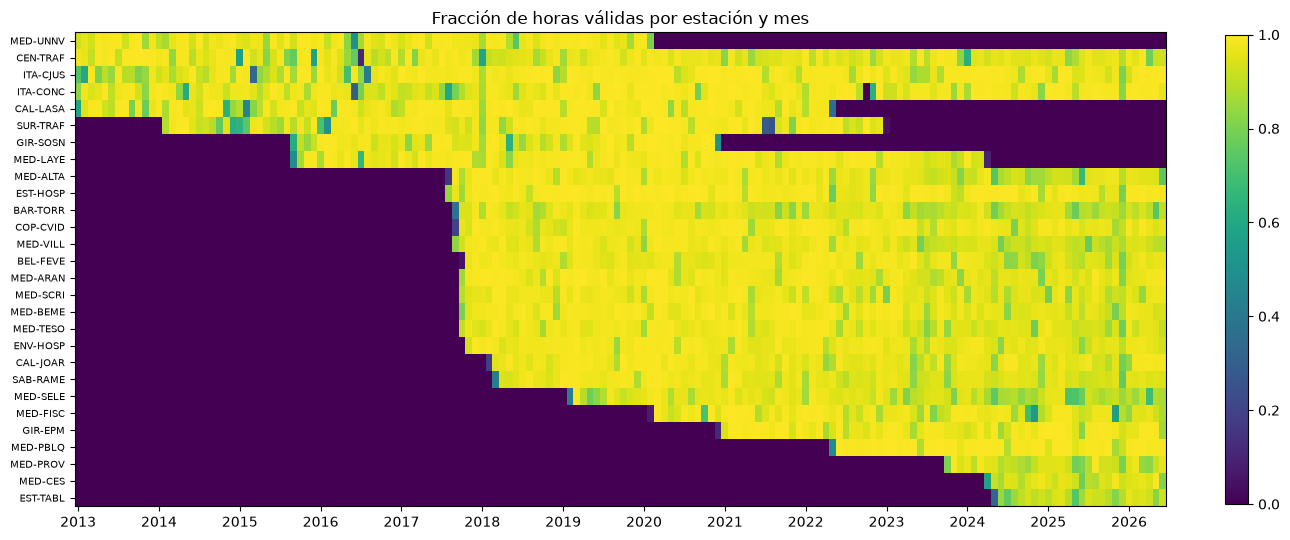

In [6]:
# % de horas faltantes por estacion y anio (solo estaciones que quedan; dentro del anio completo)
falt = limpio[estaciones].isna().groupby(limpio.index.year).mean().mul(100).round(0).astype(int)
display(falt.T)
fig, ax = plt.subplots(figsize=(13, 5.5))
mensual = limpio[estaciones].notna().groupby(limpio.index.to_period("M")).mean().T
im = ax.imshow(mensual.values, aspect="auto", cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(mensual.index))); ax.set_yticklabels(mensual.index, fontsize=7)
ticks = [i for i, p in enumerate(mensual.columns) if p.month == 1]
ax.set_xticks(ticks); ax.set_xticklabels([str(mensual.columns[i].year) for i in ticks])
ax.set_title("Fracción de horas válidas por estación y mes"); plt.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout(); plt.show()

### 2c. Promedio diario por estación (>= 75 % de horas válidas)

El promedio diario de una estación solo se calcula si ese día tiene **>= 18 de 24 horas válidas** (75 %, criterio de SIATA). Si no, el día queda faltante. Se reportan los días que se pierden por estación dentro de su vida activa.

In [7]:
horas_validas = limpio[estaciones].notna().resample("D").sum()
diario_est = limpio[estaciones].resample("D").mean().where(horas_validas >= 18)
filas = []
for c in estaciones:
    p, u = limpio[c].first_valid_index().normalize(), limpio[c].last_valid_index().normalize()
    dias_vida = len(pd.date_range(p, u, freq="D"))
    hv = horas_validas.loc[p:u, c]
    filas.append({"estacion": c, "dias_en_su_vida": dias_vida, "dias_validos": int((hv >= 18).sum()),
                  "dias_perdidos": int((hv < 18).sum()), "pct_perdidos": round((hv < 18).mean() * 100, 1),
                  "de_ellos_sin_ningun_dato": int((hv == 0).sum())})
perdidos = pd.DataFrame(filas).set_index("estacion")
display(perdidos.sort_values("pct_perdidos", ascending=False))
print("total dias-estacion perdidos:", int(perdidos.dias_perdidos.sum()), "de", int(perdidos.dias_en_su_vida.sum()),
      f"({perdidos.dias_perdidos.sum() / perdidos.dias_en_su_vida.sum():.1%})")

,dias_en_su_vida,dias_validos,dias_perdidos,pct_perdidos,de_ellos_sin_ningun_dato
estacion,,,,,
EST-TABL,775,701,74,9.5,13
MED-CES,811,743,68,8.4,10
MED-SELE,2692,2507,185,6.9,23
MED-PROV,999,931,68,6.8,14
SUR-TRAF,3255,3042,213,6.5,108
CEN-TRAF,4929,4618,311,6.3,121
MED-FISC,2316,2173,143,6.2,62
ITA-CJUS,4928,4649,279,5.7,126
ITA-CONC,4929,4655,274,5.6,129


total dias-estacion perdidos: 3393 de 81532 (4.2%)


## 3. Objetivo: estaciones y promedio del valle

**Principal**: promedio diario del valle con las estaciones que tienen **cobertura continua desde 2018**. Criterio: promedio diario válido en **>= 75 % de los días de cada año 2018-2025 y de 2026 (enero-junio)**, medido con la regla anterior. Así el promedio no cambia de composición con el tiempo (sin esto, las estaciones que entran o salen mueven el promedio sin que cambie el aire).

In [8]:
dias_ok = diario_est.notna()
cobertura = dias_ok.groupby(dias_ok.index.year).mean().loc[2018:2026]
minimo = cobertura.min()
tabla_sel = pd.DataFrame({"cobertura_minima_anual": minimo.round(3), "anio_critico": cobertura.idxmin(),
                          "continua_desde_2018": minimo >= 0.75}).sort_values("cobertura_minima_anual", ascending=False)
display(tabla_sel)
SELECCION = tabla_sel.index[tabla_sel.continua_desde_2018].tolist()
print(len(SELECCION), "estaciones continuas:", SELECCION)
print("cerca del umbral (0.70-0.80):", tabla_sel[(tabla_sel.cobertura_minima_anual >= 0.70) & (tabla_sel.cobertura_minima_anual < 0.80)].index.tolist())
print("descartadas por no ser continuas:", tabla_sel.index[~tabla_sel.continua_desde_2018].tolist())

,cobertura_minima_anual,anio_critico,continua_desde_2018
COP-CVID,0.964,2024,True
ENV-HOSP,0.964,2025,True
MED-VILL,0.959,2025,True
MED-BEME,0.951,2025,True
MED-ARAN,0.948,2023,True
EST-HOSP,0.948,2022,True
BAR-TORR,0.939,2026,True
MED-TESO,0.937,2025,True
MED-ALTA,0.937,2024,True
ITA-CJUS,0.934,2023,True


16 estaciones continuas: ['COP-CVID', 'ENV-HOSP', 'MED-VILL', 'MED-BEME', 'MED-ARAN', 'EST-HOSP', 'BAR-TORR', 'MED-TESO', 'MED-ALTA', 'ITA-CJUS', 'MED-SCRI', 'CEN-TRAF', 'BEL-FEVE', 'ITA-CONC', 'CAL-JOAR', 'SAB-RAME']
cerca del umbral (0.70-0.80): ['SAB-RAME']
descartadas por no ser continuas: ['MED-UNNV', 'SUR-TRAF', 'GIR-SOSN', 'MED-LAYE', 'CAL-LASA', 'MED-SELE', 'MED-FISC', 'GIR-EPM', 'MED-PBLQ', 'MED-PROV', 'MED-CES', 'EST-TABL']


In [9]:
# promedio del valle: media de las estaciones seleccionadas ese dia, exigiendo >= 70 % de ellas
MIN_EST = math.ceil(0.70 * len(SELECCION))
n_disp = diario_est[SELECCION].notna().sum(axis=1)
valle = diario_est[SELECCION].mean(axis=1).where(n_disp >= MIN_EST)
valle = valle.loc["2017-09-01":]
print(f"minimo de estaciones por dia: {MIN_EST} de {len(SELECCION)}")
v18 = valle.loc["2018-01-01":]
print("dias 2018-01-01 a 2026-06-30:", len(v18), "| con promedio del valle:", int(v18.notna().sum()), "| perdidos:", int(v18.isna().sum()),
      f"({v18.isna().mean():.1%})")
print("dias perdidos por anio:", v18.isna().groupby(v18.index.year).sum().to_dict())

# estaciones secundarias: una del norte, una del centro y una del sur (por el prefijo del codigo; no hay coordenadas)
SECUNDARIAS = {"norte": "COP-CVID", "centro": "CEN-TRAF", "sur": "ITA-CONC"}
print("secundarias:", SECUNDARIAS, "| todas continuas:", all(c in SELECCION for c in SECUNDARIAS.values()))
corr = pd.DataFrame({k: diario_est[c].corr(valle) for k, c in SECUNDARIAS.items()}, index=["corr_con_promedio_valle"]).T
corr["media_2018_2026"] = [diario_est.loc["2018":, c].mean() for c in SECUNDARIAS.values()]
display(corr.round(2))

minimo de estaciones por dia: 12 de 16
dias 2018-01-01 a 2026-06-30: 3103 | con promedio del valle: 3092 | perdidos: 11 (0.4%)
dias perdidos por anio: {2018: 4, 2019: 0, 2020: 0, 2021: 0, 2022: 0, 2023: 2, 2024: 0, 2025: 5, 2026: 0}
secundarias: {'norte': 'COP-CVID', 'centro': 'CEN-TRAF', 'sur': 'ITA-CONC'} | todas continuas: True


,corr_con_promedio_valle,media_2018_2026
norte,0.94,14.12
centro,0.92,26.05
sur,0.90,17.89


**Justificación de las secundarias [SUPUESTO]**: los archivos no traen coordenadas, así que norte/centro/sur se asigna por el municipio del código: `COP-CVID` (Copacabana, norte), `CEN-TRAF` (Medellín centro, tráfico) e `ITA-CONC` (Itagüí, sur del área central). Las tres son continuas desde 2018 (`ITA-CONC` y `CEN-TRAF` tienen datos desde 2013). `ITA-CONC` coincide con el punto sur de Open-Meteo (Itagüí). `CAL-JOAR` (Caldas, más al sur) también es continua (cobertura mínima 83 %), y `SAB-RAME` está cerca del umbral (77 %).

## 4. Estacionalidad

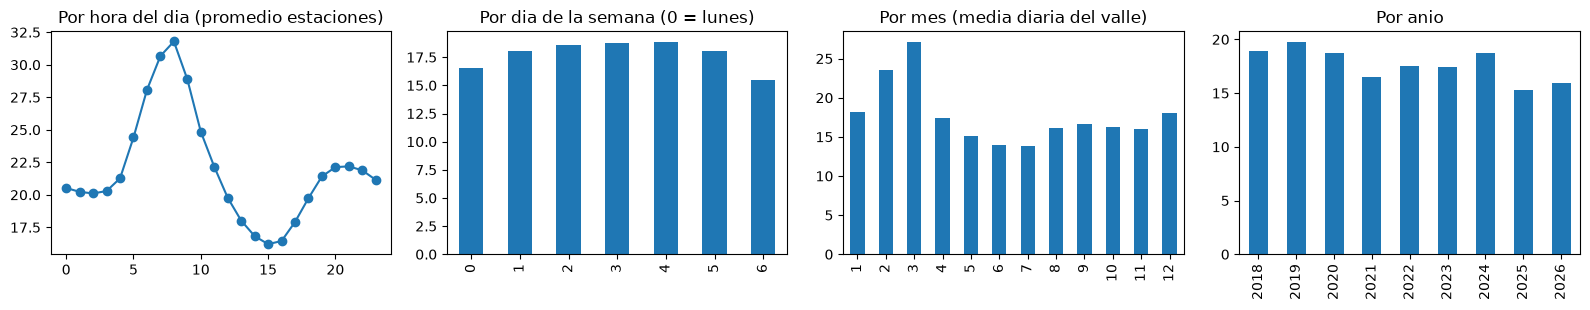

fecha_hora,1,2,3,4,5,6,7,8,9,10,11,12
media,18.2,23.5,27.1,17.4,15.1,14.0,13.8,16.1,16.7,16.2,16.0,18.1
mediana,17.6,21.8,25.2,16.1,15.0,13.9,13.5,15.5,16.1,15.7,15.8,17.8
p90,22.9,34.1,43.3,24.3,19.0,17.6,16.9,21.5,21.3,21.2,20.3,22.2
dias_sobre_37,0.0,13.0,46.0,3.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


fecha_hora,2018,2019,2020,2021,2022,2023,2024,2025,2026
mean,19.0,19.8,18.7,16.5,17.5,17.4,18.8,15.3,16.0
median,17.6,17.6,16.0,15.8,16.7,16.3,16.9,14.7,15.4
count,361.0,365.0,366.0,365.0,365.0,363.0,366.0,360.0,181.0
dias_sobre_37,7.0,16.0,26.0,1.0,2.0,2.0,9.0,0.0,0.0


norma diaria 37 ug/m3 (la define el usuario; Res. 2254 de 2017 [SUPUESTO]): dias del valle sobre la norma: 63 de 3092 (2.0%)


In [10]:
perfil_h = limpio[SELECCION].mean(axis=1).groupby(limpio.index.hour).mean()
v_d = valle.loc["2018-01-01":].dropna()
por_dsem = v_d.groupby(v_d.index.dayofweek).mean()
por_mes = v_d.groupby(v_d.index.month).agg(["mean", "median", lambda s: s.quantile(.9)])
por_mes.columns = ["media", "mediana", "p90"]
por_mes["dias_sobre_37"] = (v_d > 37).groupby(v_d.index.month).sum()
por_anio = v_d.groupby(v_d.index.year).agg(["mean", "median", "count"])
por_anio["dias_sobre_37"] = (v_d > 37).groupby(v_d.index.year).sum()

fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
perfil_h.plot(ax=ax[0], marker="o"); ax[0].set_title("Por hora del dia (promedio estaciones)")
por_dsem.plot(ax=ax[1], kind="bar"); ax[1].set_title("Por dia de la semana (0 = lunes)")
por_mes.media.plot(ax=ax[2], kind="bar"); ax[2].set_title("Por mes (media diaria del valle)")
por_anio["mean"].plot(ax=ax[3], kind="bar"); ax[3].set_title("Por anio")
for a in ax:
    a.set_xlabel("")
plt.tight_layout(); plt.show()
display(por_mes.round(1).T)
display(por_anio.round(1).T)
print("norma diaria 37 ug/m3 (la define el usuario; Res. 2254 de 2017 [SUPUESTO]): dias del valle sobre la norma:", int((v_d > 37).sum()), "de", len(v_d),
      f"({(v_d > 37).mean():.1%})")

## 5. Meteorología (Open-Meteo, archivo histórico)

3 puntos del valle, sin API key, con caché en disco (un archivo por punto y año). Variables horarias: temperatura, humedad relativa, precipitación, velocidad y dirección del viento a 10 m, presión a nivel del mar y altura de la capa límite. El 2026-10-15 se verificó con una sonda que la API `archive` **sí** entrega `boundary_layer_height` para esta zona.

In [11]:
PUNTOS = {"norte_girardota": (6.38, -75.45), "centro_medellin": (6.25, -75.57), "sur_itagui": (6.17, -75.61)}
VARS = ["temperature_2m", "relative_humidity_2m", "precipitation", "wind_speed_10m", "wind_direction_10m", "pressure_msl", "boundary_layer_height"]
ANIOS = list(range(2018, 2027))


def bajar_om(nombre, lat, lon, anio):
    f = METEO / f"{nombre}_{anio}.json"
    if f.exists():
        return json.loads(f.read_text(encoding="utf-8"))
    fin = f"{anio}-12-31" if anio < 2026 else "2026-06-30"
    prm = {"latitude": lat, "longitude": lon, "start_date": f"{anio}-01-01", "end_date": fin,
           "hourly": ",".join(VARS), "timezone": "America/Bogota", "wind_speed_unit": "ms"}
    for intento in range(3):
        try:
            r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=prm, timeout=30)
        except requests.RequestException:
            time.sleep(5 * (intento + 1))
            continue
        if r.status_code == 429:
            raise RuntimeError("Open-Meteo limito el uso (429): detenerse y avisar")
        if r.status_code == 200:
            f.write_text(r.text, encoding="utf-8")
            time.sleep(1.5)
            return r.json()
        time.sleep(5 * (intento + 1))
    raise RuntimeError(f"fallo {nombre} {anio}: {r.status_code} {r.text[:150]}")


t0 = time.time()
total = len(PUNTOS) * len(ANIOS)
hechas = 0
met_h = {}
for nombre, (lat, lon) in PUNTOS.items():
    trozos = []
    for anio in ANIOS:
        j = bajar_om(nombre, lat, lon, anio)
        h = pd.DataFrame(j["hourly"]); h["time"] = pd.to_datetime(h["time"])
        trozos.append(h.set_index("time"))
        hechas += 1
        if hechas % 5 == 0 or hechas == total:
            print(f"  open-meteo: {hechas}/{total} solicitudes | {time.time() - t0:.0f} s | elevacion usada {nombre}: {j.get('elevation')} m")
    met_h[nombre] = pd.concat(trozos)
print("hecho en", round(time.time() - t0), "s")
for n, h in met_h.items():
    print(n, h.shape, "| nulos por variable:", h.isna().sum()[h.isna().sum() > 0].to_dict() or "ninguno")
pbl_nul = met_h["centro_medellin"].boundary_layer_height.isna()
print("altura de capa limite: horas nulas por anio (centro):", pbl_nul.groupby(pbl_nul.index.year).sum().to_dict())
nul_idx = pbl_nul[pbl_nul].index
print("horas sin altura de capa limite: desde", nul_idx.min(), "hasta", nul_idx.max(), "| total:", len(nul_idx),
      "| dias completos sin dato:", int((pbl_nul.resample("D").sum() == 24).sum()))

  open-meteo: 5/27 solicitudes | 0 s | elevacion usada norte_girardota: 1382.0 m
  open-meteo: 10/27 solicitudes | 0 s | elevacion usada centro_medellin: 1483.0 m


  open-meteo: 15/27 solicitudes | 0 s | elevacion usada centro_medellin: 1483.0 m


  open-meteo: 20/27 solicitudes | 0 s | elevacion usada sur_itagui: 1570.0 m
  open-meteo: 25/27 solicitudes | 0 s | elevacion usada sur_itagui: 1570.0 m
  open-meteo: 27/27 solicitudes | 0 s | elevacion usada sur_itagui: 1570.0 m
hecho en 0 s
norte_girardota (74472, 7) | nulos por variable: {'boundary_layer_height': 4368}
centro_medellin (74472, 7) | nulos por variable: {'boundary_layer_height': 4368}
sur_itagui (74472, 7) | nulos por variable: {'boundary_layer_height': 4368}
altura de capa limite: horas nulas por anio (centro): {2018: 0, 2019: 0, 2020: 0, 2021: 0, 2022: 0, 2023: 5, 2024: 4363, 2025: 0, 2026: 0}
horas sin altura de capa limite: desde 2023-12-31 19:00:00 hasta 2024-06-30 18:00:00 | total: 4368 | dias completos sin dato: 181


In [12]:
def agregar_diario(h):
    d = pd.DataFrame(index=h.resample("D").size().index)
    d["temp_media"] = h.temperature_2m.resample("D").mean()
    d["temp_max"] = h.temperature_2m.resample("D").max()
    d["temp_min"] = h.temperature_2m.resample("D").min()
    d["hum_media"] = h.relative_humidity_2m.resample("D").mean()
    d["precip_mm"] = h.precipitation.resample("D").sum(min_count=20)
    d["viento_medio"] = h.wind_speed_10m.resample("D").mean()
    d["viento_max"] = h.wind_speed_10m.resample("D").max()
    rad = np.deg2rad(h.wind_direction_10m)
    d["viento_u"] = (-h.wind_speed_10m * np.sin(rad)).resample("D").mean()
    d["viento_v"] = (-h.wind_speed_10m * np.cos(rad)).resample("D").mean()
    d["presion"] = h.pressure_msl.resample("D").mean()
    d["pbl_media"] = h.boundary_layer_height.resample("D").mean()
    d["pbl_max"] = h.boundary_layer_height.resample("D").max()
    return d


met_d = {n: agregar_diario(h) for n, h in met_h.items()}
met_valle = sum(met_d.values()) / len(met_d)      # promedio de los 3 puntos
print("meteorologia diaria del valle:", met_valle.shape, "| nulos:", int(met_valle.isna().sum().sum()))
display(met_valle.describe().T[["mean", "std", "min", "max"]].round(2))
display(pd.DataFrame({k: met_d[k].temp_media.corr(met_d["centro_medellin"].temp_media) for k in met_d}, index=["corr_temp_con_centro"]).round(3))
ram("meteorologia lista")

meteorologia diaria del valle: (3103, 12) | nulos: 362


,mean,std,min,max
temp_media,20.02,0.93,17.65,23.83
temp_max,25.73,1.71,19.57,31.93
temp_min,16.15,0.86,11.60,18.97
hum_media,85.01,5.29,62.33,96.44
precip_mm,6.39,5.24,0.00,54.50
viento_medio,1.10,0.29,0.52,2.26
viento_max,2.31,0.51,1.13,4.26
viento_u,-0.59,0.49,-2.13,1.11
viento_v,-0.13,0.18,-0.67,0.62
presion,1014.80,1.22,1009.96,1018.76


,norte_girardota,centro_medellin,sur_itagui
corr_temp_con_centro,0.947,1.0,0.832


[RAM] meteorologia lista: actual 339 MB | pico 445 MB


## 6. Baseline con validación temporal

- **Objetivo**: PM2.5 promedio diario del día D (promedio del valle; también 3 estaciones). Se pronostica D con lo que se sabe hasta el día D-1.
- **Split temporal** (sin shuffle): train = 2018-01-01 a 2024-12-31, test = 2025-01-01 a 2026-06-30.
- **a) Persistencia**: PM2.5(D) = PM2.5(D-1).
- **b) `HistGradientBoostingRegressor` con lags de PM2.5** (D-1, D-2, D-3, D-7) + meteorología + calendario.
- **c) `HistGradientBoostingRegressor` SIN lags** (solo meteorología + calendario): simula el modelo desplegado sin datos en vivo de PM2.5.
- Hiperparámetros por defecto, `early_stopping=False` (el early stopping automático usa un 10 % aleatorio del train, no temporal).
- Métricas sobre los días del test que tienen objetivo **y** PM2.5(D-1) (para que las tres comparaciones usen exactamente las mismas filas). Se reporta además el **recall de días > 37 µg/m³** (norma diaria). Como el test puede no tener ningún día sobre 37, se agrega un umbral complementario: el **percentil 95 del train**.
- **Fuga leve [VERIFICADO en el diseño]**: la meteorología es la **observada** (reanálisis ERA5/IFS) del propio día D, y en producción solo habrá pronóstico. b) y c) están algo optimistas. Calendario: solo día de la semana, mes y día del año; no se incluyen feriados.

In [13]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

INI_TRAIN, FIN_TRAIN, INI_TEST, FIN_TEST = "2018-01-01", "2024-12-31", "2025-01-01", "2026-06-30"
cal_idx = pd.date_range("2018-01-01", FIN_TEST, freq="D")


def construir(y):
    y = y.reindex(pd.date_range("2017-09-01", FIN_TEST, freq="D"))
    df = pd.DataFrame({"y": y})
    for k in (1, 2, 3, 7):
        df[f"pm_lag{k}"] = y.shift(k)
    df = df.loc[INI_TRAIN:]
    met = met_valle.loc[INI_TRAIN:FIN_TEST]
    df = df.join(met).join(met.shift(1).add_suffix("_d1"))
    df["dia_semana"] = df.index.dayofweek
    df["es_finde"] = (df.index.dayofweek >= 5).astype(int)
    df["mes"] = df.index.month
    df["dia_anio"] = df.index.dayofyear
    return df


COL_LAG = ["pm_lag1", "pm_lag2", "pm_lag3", "pm_lag7"]


def evaluar(df, nombre, umbral=37.0):
    tr = df.loc[INI_TRAIN:FIN_TRAIN].dropna(subset=["y"])
    te = df.loc[INI_TEST:FIN_TEST].dropna(subset=["y", "pm_lag1"])
    feats_b = [c for c in df.columns if c != "y"]
    feats_c = [c for c in feats_b if c not in COL_LAG]
    feats_c2 = [c for c in feats_c if not c.startswith("pbl")]
    t0 = time.perf_counter()
    mb = HistGradientBoostingRegressor(early_stopping=False, random_state=SEED).fit(tr[feats_b], tr.y)
    mc = HistGradientBoostingRegressor(early_stopping=False, random_state=SEED).fit(tr[feats_c], tr.y)
    mc2 = HistGradientBoostingRegressor(early_stopping=False, random_state=SEED).fit(tr[feats_c2], tr.y)
    seg = time.perf_counter() - t0
    pred = {"a_persistencia": te.pm_lag1.to_numpy(), "b_con_lags": mb.predict(te[feats_b]), "c_sin_lags": mc.predict(te[feats_c]),
            "c2_sin_lags_sin_pbl (diagnostico)": mc2.predict(te[feats_c2]),
            "ref_media_train": np.full(len(te), tr.y.mean()),
            "ref_media_del_mes": te.mes.map(tr.groupby("mes").y.mean()).to_numpy()}
    real = te.y.to_numpy()
    u95 = float(tr.y.quantile(0.95))
    crit = te.mes.isin([2, 3, 4]).to_numpy()
    filas = []
    for k, p_ in pred.items():
        sobre = real > umbral
        filas.append({"serie": nombre, "modelo": k, "MAE": np.abs(real - p_).mean(), "MAE_feb_abr": np.abs(real - p_)[crit].mean() if crit.any() else np.nan,
                      "n_test": len(te), "dias_reales_sobre_37": int(sobre.sum()), "dias_predichos_sobre_37": int((p_ > umbral).sum()),
                      "aciertos": int(((p_ > umbral) & sobre).sum()),
                      "recall_sobre_37": ((p_ > umbral) & sobre).sum() / sobre.sum() if sobre.sum() else np.nan,
                      "precision": ((p_ > umbral) & sobre).sum() / max((p_ > umbral).sum(), 1) if (p_ > umbral).sum() else np.nan,
                      "umbral_p95_train": u95, "dias_reales_sobre_p95": int((real > u95).sum()),
                      "aciertos_p95": int(((p_ > u95) & (real > u95)).sum()),
                      "recall_p95": ((p_ > u95) & (real > u95)).sum() / (real > u95).sum() if (real > u95).sum() else np.nan})
    return pd.DataFrame(filas), (mb, mc, te, feats_b, feats_c, seg, len(tr))


t_total = time.perf_counter()
series = {"valle_promedio": valle}
series.update({f"estacion_{k}_{c}": diario_est[c] for k, c in SECUNDARIAS.items()})
res, modelos = [], {}
for nombre, s in series.items():
    r, m = evaluar(construir(s), nombre)
    res.append(r); modelos[nombre] = m
    print(f"  listo {nombre}: n_train={m[6]}, n_test={int(r.n_test.iloc[0])}, entrenamiento {m[5]:.1f} s")
resultados = pd.concat(res, ignore_index=True)
print(f"tiempo total: {time.perf_counter() - t_total:.1f} s")
ram("tras el baseline")

  listo valle_promedio: n_train=2551, n_test=538, entrenamiento 0.7 s


  listo estacion_norte_COP-CVID: n_train=2502, n_test=532, entrenamiento 0.8 s


  listo estacion_centro_CEN-TRAF: n_train=2436, n_test=494, entrenamiento 0.7 s


  listo estacion_sur_ITA-CONC: n_train=2441, n_test=525, entrenamiento 0.7 s
tiempo total: 3.0 s
[RAM] tras el baseline: actual 419 MB | pico 445 MB


In [14]:
vista = resultados.copy()
vista["MAE"] = vista.MAE.round(2); vista["MAE_feb_abr"] = vista.MAE_feb_abr.round(2)
vista["umbral_p95_train"] = vista.umbral_p95_train.round(1); vista["recall_p95"] = vista.recall_p95.round(2)
vista["recall_sobre_37"] = vista.recall_sobre_37.round(2); vista["precision"] = vista.precision.round(2)
display(vista[vista.serie == "valle_promedio"].set_index("modelo").drop(columns="serie").T)
display(vista[vista.serie != "valle_promedio"].set_index(["serie", "modelo"])[["MAE", "MAE_feb_abr", "n_test", "dias_reales_sobre_37", "dias_predichos_sobre_37", "aciertos", "recall_sobre_37", "precision"]])

modelo,a_persistencia,b_con_lags,c_sin_lags,c2_sin_lags_sin_pbl (diagnostico),ref_media_train,ref_media_del_mes
MAE,2.40,2.14,4.22,3.90,4.04,4.03
MAE_feb_abr,2.66,2.57,6.22,6.02,3.55,6.55
n_test,538.00,538.00,538.00,538.00,538.00,538.00
dias_reales_sobre_37,0.00,0.00,0.00,0.00,0.00,0.00
dias_predichos_sobre_37,0.00,0.00,5.00,1.00,0.00,0.00
aciertos,0.00,0.00,0.00,0.00,0.00,0.00
recall_sobre_37,NaN,NaN,NaN,NaN,NaN,NaN
precision,NaN,NaN,0.00,0.00,NaN,NaN
umbral_p95_train,32.00,32.00,32.00,32.00,32.00,32.00
dias_reales_sobre_p95,0.00,0.00,0.00,0.00,0.00,0.00


MAE  MAE_feb_abr  n_test  dias_reales_sobre_37  dias_predichos_sobre_37  aciertos  recall_sobre_37  precision
serie                    modelo                                                                                                                                           
estacion_norte_COP-CVID  a_persistencia                     2.32         2.55     532                     0                        0         0              NaN        NaN
                         b_con_lags                         2.25         2.61     532                     0                        0         0              NaN        NaN
                         c_sin_lags                         4.36         7.01     532                     0                        4         0              NaN       0.00
                         c2_sin_lags_sin_pbl (diagnostico)  4.28         6.72     532                     0                        0         0              NaN        NaN
                         ref_media_train                    4.17         3.42     532                     0                        0         0              NaN        NaN
                         ref_media_del_mes                  4.48         7.57     532                     0                        0         0              NaN        NaN
estacion_centro_CEN-TRAF a_persistencia                     4.20         4.60     494                    10                       10         3              0.3       0.30
                         b_con_lags                         3.33         3.94     494                    10                        9         3              0.3       0.33
                         c_sin_lags                         5.23         8.02     494                    10                       47         5              0.5       0.11
                         c2_sin_lags_sin_pbl (diagnostico)  5.03         7.62     494                    10                       45         4              0.4       0.09
                         ref_media_train                    5.27         5.09     494                    10                        0         0              0.0        NaN
                         ref_media_del_mes                  5.04         7.32     494                    10                       62         9              0.9       0.15
estacion_sur_ITA-CONC    a_persistencia                     3.10         3.60     525                     0                        0         0              NaN        NaN
                         b_con_lags                         2.61         3.02     525                     0                        0         0              NaN        NaN
                         c_sin_lags                         4.24         6.39     525                     0                       13         0              NaN       0.00
                         c2_sin_lags_sin_pbl (diagnostico)  3.91         5.40     525                     0                        3         0              NaN       0.00
                         ref_media_train                    3.75         3.90     525                     0                        0         0              NaN        NaN
                         ref_media_del_mes                  3.79         5.17     525                     0                        0         0              NaN        NaN

In [15]:
# MAE del valle en el test por periodo, y los modelos frente a la persistencia
mb, mc, te, fb, fc, _, _ = modelos["valle_promedio"]
pers = (te.y - te.pm_lag1).abs()
b_ = (te.y - mb.predict(te[fb])).abs()
c_ = (te.y - mc.predict(te[fc])).abs()
por = pd.DataFrame({"persistencia": pers, "b_con_lags": b_, "c_sin_lags": c_}).groupby(te.index.to_period("Q")).mean().round(2)
display(por.T)
print("y promedio en el test:", round(te.y.mean(), 2), "| desv. tipica:", round(te.y.std(), 2))

# importancia por permutacion (valle, test)
for nombre_m, m_, f_ in [("b_con_lags", mb, fb), ("c_sin_lags", mc, fc)]:
    pi = permutation_importance(m_, te[f_], te.y, scoring="neg_mean_absolute_error", n_repeats=10, random_state=SEED)
    imp = pd.Series(pi.importances_mean, index=f_).sort_values(ascending=False).head(8)
    print(f"\ntop 8 features ({nombre_m}), aumento del MAE al permutar:")
    display(imp.round(3).to_frame("aumento_MAE"))

,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
persistencia,2.65,2.17,1.96,2.45,2.77,2.42
b_con_lags,2.59,1.94,1.96,1.85,2.45,2.07
c_sin_lags,5.40,3.03,4.11,2.86,6.73,3.15


y promedio en el test: 15.5 | desv. tipica: 3.83



top 8 features (b_con_lags), aumento del MAE al permutar:


,aumento_MAE
pm_lag1,1.024
dia_semana,0.233
viento_u,0.184
dia_anio,0.124
precip_mm_d1,0.055
viento_medio,0.038
pbl_max_d1,0.038
viento_v,0.033



top 8 features (c_sin_lags), aumento del MAE al permutar:


,aumento_MAE
mes,1.405
dia_anio,1.335
dia_semana,0.176
pbl_media_d1,0.173
viento_u_d1,0.169
pbl_max_d1,0.134
viento_u,0.098
hum_media_d1,0.087


## Lectura del baseline

Test = 2025-01-01 a 2026-06-30 (538 días del promedio del valle con objetivo y PM2.5 del día anterior). Train = 2018-2024.

**Promedio del valle (objetivo principal)**

| Modelo | MAE (µg/m³) | MAE feb-abr |
|---|---|---|
| a) Persistencia | 2,40 | 2,66 |
| b) HGB con lags de PM2.5 + meteorología + calendario | **2,14** | 2,57 |
| c) HGB sin lags (meteorología + calendario) | 4,22 | 6,22 |
| Referencia: media del train | 4,04 | 3,55 |

- **[VERIFICADO] b) le gana a la persistencia, pero poco**: baja el MAE 11 % en el valle (de 2,40 a 2,14), con ventaja en casi todos los trimestres y casi nula en feb-abr (2,57 vs 2,66). Por estación la ganancia es 3 % (`COP-CVID`), 16 % (`ITA-CONC`) y 21 % (`CEN-TRAF`). No es una mejora clara.
- **[VERIFICADO] c) no tiene habilidad por encima de la climatología**: su MAE (4,22) es peor que la persistencia y ligeramente peor que la media del train (4,04) y que la media del mes (4,03). En feb-abr es mucho peor que la media del train (6,22 vs 3,55). La importancia por permutación lo explica: las features que más pesan en c) son `mes` y `dia_anio`; la meteorología aporta poco. Sin PM2.5 reciente, el modelo solo reproduce la estacionalidad y se equivoca justo en las épocas críticas. Quitar la capa límite (variante diagnóstica c2) lo mejora algo (3,90) pero sigue sin ser claramente mejor que la climatología. **Esto es con meteorología observada**, así que con pronóstico sería igual o peor.
- **[VERIFICADO] b) vive de `pm_lag1`** (quitarlo sube el MAE en 1,02 µg/m³; sigue `dia_semana`, 0,23). En producción exige tener el PM2.5 del día anterior en vivo.

**Recall de días > 37 µg/m³ (norma diaria)**

- **[VERIFICADO] El promedio del valle no tiene ningún día sobre 37 en el test** (ni sobre 32, el percentil 95 del train), así que el recall **no se puede calcular** para el objetivo principal. El test es un periodo más limpio: media 15,5 µg/m³ frente a ~18 en el train (2018-2020 fueron años altos, ~19).
- Solo `CEN-TRAF` tiene días sobre 37 en el test (10 de 494). Con tan pocos casos las cifras son frágiles: persistencia y b) detectan 3 de 10 (recall 0,30; precisión 0,30 y 0,33); c) detecta 5 de 10 pero con 47 alertas (precisión 0,11); la media del mes detecta 9 de 10 con 62 alertas (precisión 0,15). **El recall solo es engañoso**: hay que mirarlo junto con la precisión.
- Para el proyecto final la norma de 37 µg/m³ es un criterio débil para evaluar sobre el promedio del valle: casi no hay episodios recientes. Convendría evaluar episodios por estación o con un umbral más bajo.

**Estacionalidad y deriva** [VERIFICADO]: marzo es el mes crítico (media 27,1; 46 de 63 días sobre 37 en 2018-2026) y febrero-abril concentra los episodios. **Octubre-noviembre no son críticos** en este dato (media ~16, ningún día sobre 37). La media anual cae de ~19 (2018-2020) a 15,3 (2025), de modo que el test tiene un nivel distinto al del train.

**Capa límite [VERIFICADO]**: `boundary_layer_height` existe en el archivo de Open-Meteo, pero **faltan 181 días completos (enero a junio de 2024)** en los tres puntos, dentro del train. HGB lo maneja como valor faltante; hay que revisarlo antes del modelo final.

## Limitaciones y fuga

- **Meteorología observada [VERIFICADO]**: es el reanálisis (ERA5/IFS) del propio día D, que en producción no existe; allí solo habría pronóstico. b) y c) están optimistas.
- **¿Pronósticos históricos para entrenar de forma realista?** Sí, con límites (docs de Open-Meteo y sondas del 2026-10-15): la **Historical Forecast API** responde desde 2021 (las docs dicen "alrededor de 2021" y "desde 2022"); es una serie continua que une las primeras horas de cada corrida, así que se parece más a un análisis que a un pronóstico a 24 h, y las docs la desaconsejan para series largas por cambios de versión del modelo. La **Previous Runs API** da el pronóstico con 1 a 7 días de antelación (`*_previous_day1`...) pero **desde enero de 2024**. Un entrenamiento realista tendría ~2,5 años (unos 900 días). En la sonda de 2023 la capa límite de la Historical Forecast API vino vacía.
- **Calendario**: sin feriados (no se instaló una librería). Es una mejora pendiente.
- **Validación interna**: se desactivó el early stopping (usa un 10 % aleatorio del train).
- **Unidades [VERIFICADO indirectamente]**: µg/m³; los archivos no las declaran.
- **Estaciones secundarias [SUPUESTO]**: norte/centro/sur se asignó por el prefijo del código (no hay coordenadas).
- **Variables no incluidas**: radiación, nubosidad, feriados, tráfico, incendios y calidad del aire regional (humo, polvo del Sahara) no se probaron.

## Costo computacional (dataset completo)

El dataset completo son **14,6 MB** de CSV y ~3.100 filas diarias: es pequeño. Cargar y limpiar tarda ~3 s; descargar la meteorología (27 solicitudes) ~2 min; entrenar los modelos de una serie, menos de 1 s; todo el notebook ~2 min con la descarga y **pico de RAM ~445 MB**. Cabe en cualquier laptop; no hace falta GPU.

## Actualización automática (para el reajuste)

- **Meteorología**: Open-Meteo es automatizable sin key (límite de uso razonable).
- **PM2.5**: los términos de SIATA exigen **coordinar con su equipo técnico cualquier descarga automatizada** (11.2) y el `robots.txt` del repositorio prohíbe el acceso automatizado. Para el reajuste automático hay que pedir autorización a `solicitud.datos@siata.gov.co`. La alternativa sin trámite es SISAIRE (IDEAM, datos.gov.co), pero está desactualizada (hasta 2024-12-31).


## 7. Resumen para el checkpoint

In [16]:
print("Estaciones del objetivo principal (continuas desde 2018):", SELECCION)
print("Secundarias:", SECUNDARIAS)
print("\nCalidad: ceros =", int(tot.ceros), "| en rachas >= 3 h:", int(tot.ceros_en_rachas_ge3), "| aislados:", int(tot.ceros_aislados_1a2))
print("Dias del valle perdidos 2018-2026:", int(v18.isna().sum()), "de", len(v18))
print("\nMAE y recall (>37) del promedio del valle, test 2025-01 a 2026-06:")
display(vista[vista.serie == "valle_promedio"].set_index("modelo")[["MAE", "MAE_feb_abr", "n_test", "dias_reales_sobre_37", "dias_predichos_sobre_37", "aciertos", "recall_sobre_37", "umbral_p95_train", "dias_reales_sobre_p95", "aciertos_p95", "recall_p95"]])
ram("final")

Estaciones del objetivo principal (continuas desde 2018): ['COP-CVID', 'ENV-HOSP', 'MED-VILL', 'MED-BEME', 'MED-ARAN', 'EST-HOSP', 'BAR-TORR', 'MED-TESO', 'MED-ALTA', 'ITA-CJUS', 'MED-SCRI', 'CEN-TRAF', 'BEL-FEVE', 'ITA-CONC', 'CAL-JOAR', 'SAB-RAME']
Secundarias: {'norte': 'COP-CVID', 'centro': 'CEN-TRAF', 'sur': 'ITA-CONC'}

Calidad: ceros = 5036 | en rachas >= 3 h: 115 | aislados: 4921
Dias del valle perdidos 2018-2026: 11 de 3103

MAE y recall (>37) del promedio del valle, test 2025-01 a 2026-06:


,MAE,MAE_feb_abr,n_test,dias_reales_sobre_37,dias_predichos_sobre_37,aciertos,recall_sobre_37,umbral_p95_train,dias_reales_sobre_p95,aciertos_p95,recall_p95
modelo,,,,,,,,,,,
a_persistencia,2.40,2.66,538,0,0,0,NaN,32.0,0,0,NaN
b_con_lags,2.14,2.57,538,0,0,0,NaN,32.0,0,0,NaN
c_sin_lags,4.22,6.22,538,0,5,0,NaN,32.0,0,0,NaN
c2_sin_lags_sin_pbl (diagnostico),3.90,6.02,538,0,1,0,NaN,32.0,0,0,NaN
ref_media_train,4.04,3.55,538,0,0,0,NaN,32.0,0,0,NaN
ref_media_del_mes,4.03,6.55,538,0,0,0,NaN,32.0,0,0,NaN


[RAM] final: actual 419 MB | pico 445 MB
